In [ ]:
# All imports
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency #import chi squared
from scipy.stats import f_oneway
from scipy.stats import tukey_hsd
import seaborn as sns
import scipy.stats as stats

df = pd.read_csv("cars.csv")

rows,cols = df.shape

names = []

for i in range(rows):

    fullName = ""

    fullName = fullName + df.loc[i, "First Name"]

    fullName = fullName + " " + df.loc[i, "Last Name"]

    names.append(fullName)

df.insert(0, "Name", names)

df = df[["Name", "Country", "Car Brand", "Car Model", "Car Color", "Year of Manufacture", "Credit Card Type"]]

# Check for duplicates 
print(f"Duplicates: {df.duplicated().sum()}")

# Check for null values
print("Null values:")
display(df.isnull().sum())

display(df.head(5))


Duplicates: 0
Null values:


Name                   0
Country                0
Car Brand              0
Car Model              0
Car Color              0
Year of Manufacture    0
Credit Card Type       0
dtype: int64

,Name,Country,Car Brand,Car Model,Car Color,Year of Manufacture,Credit Card Type
0,Yetty Arghent,Indonesia,Ford,Club Wagon,Teal,1993,mastercard
1,Crystal Bosworth,China,Cadillac,Escalade ESV,Fuscia,2007,mastercard
2,Monro Houdhury,Indonesia,Mazda,Miata MX-5,Orange,2009,maestro
3,Bowie Clair,China,Audi,A4,Orange,2005,instapayment
4,Myrvyn McAllister,Czech Republic,Nissan,Maxima,Pink,1994,maestro


## ANALYSIS 1: DISTRIBUTION OF CAR MANUFACTURING YEARS

We want to examine the distribution of car manufacturing years in the dataset. We will use Z-scores to find any potential outliers and determine how much the old/new cars affect the average manufacturing year. This will help us better understand our dataset and decide whether to remove these outliers or not

In [82]:
df['Year of Manufacture'].describe()


count    30000.000000
mean      2000.247500
std          9.131398
min       1909.000000
25%       1995.000000
50%       2002.000000
75%       2007.000000
max       2013.000000
Name: Year of Manufacture, dtype: float64

In [83]:
# Z-SCORES
# Trying to find any outliers ; Keep count of # of outliers
mean = df['Year of Manufacture'].mean()
std = df['Year of Manufacture'].std()

num = 0

for i in df.index:
    year = df.loc[i, 'Year of Manufacture']
    car_brand = df.loc[i, 'Car Brand']
    model = df.loc[i, 'Car Model']
    
    zscore = (year - mean) / std
    if abs(zscore) > 3:
        num += 1

print(f"Num of outliers: {num}")
# Percent of outliers that make up the data
percent_of_outliers = (num / len(df)) * 100
print(f"Percent of outliers that make up the data : {percent_of_outliers}")


Num of outliers: 538
Percent of outliers that make up the data : 1.7933333333333332


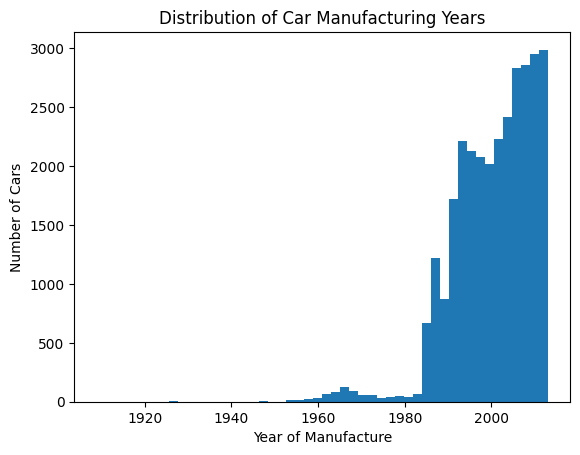

In [84]:
plt.hist(df['Year of Manufacture'], bins=50)
plt.xlabel('Year of Manufacture')
plt.ylabel('Number of Cars')
plt.title('Distribution of Car Manufacturing Years')
plt.show()

In [85]:
# Want to see what the mean would be without outliers

df_copy = df.copy()

zscore = ((df_copy['Year of Manufacture']) - mean) / std

df_copy = df_copy[abs(zscore) <= 3]

no_outliers_mean = (df_copy['Year of Manufacture'].mean())

print(f"Mean with no outliers: {no_outliers_mean}")
print(f"Mean with outliers: {mean}")

difference = no_outliers_mean - mean
print(f"Difference in means: {difference}")



Mean with no outliers: 2000.8941687597583
Mean with outliers: 2000.2475
Difference in means: 0.6466687597583132


## CONCLUSION ON DISTRIBUTION OF CAR MANUFACTURING YEARS

Most cars in the dataset were manufactured in recent years so our distrubution was left skewed.
 The mean manufacturing year was  2000.24, while the median was 2002. 
 Using Z-scores we found 538 potential outliers which made up about 1.79% of our dataset. 
 After excluding the outliers, the mean increased to 2000.89, thats only a 0.65 year difference.
This shows that the outliers have a relatively small impact on the mean. 
We decided to keep the outliers in our original dataset because older manufacturing years can still be valid

## HYPOTHESIS TEST 1: Car Model and Credit Card Type

Is there a relationship between the data's Car Model and Credit Card Type? In order to determine this, we will perform a hypothesis Test with the following hypothesis:

H0: There is an independent relationship between Car Model and Credit Card Type.
Ha: There is NOT an independent relationship between Car Model and Credit Card Type.

In order to conduct this hypothesis test, we will perform a Chi-Squared Test, as we are comparing categorical variables. We will set our alpha value at 0.05.

In [86]:
# Code for Hypothesis Testing

# Create a contingency table
table = pd.crosstab(df["Car Model"], df["Credit Card Type"])

# Perform the chi-squared test
chi2, p_value, dof, expected = chi2_contingency(table)

# Set significance level
alpha = 0.05

print("Chi-squared statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

if p_value <= alpha:
    print("Reject H0: There is evidence of an association.")
else:
    print("Fail to reject H0: Insufficient evidence of an association.")

Chi-squared statistic: 14663.58221770675
P-value: 0.9915174195849424
Degrees of freedom: 15075
Fail to reject H0: Insufficient evidence of an association.


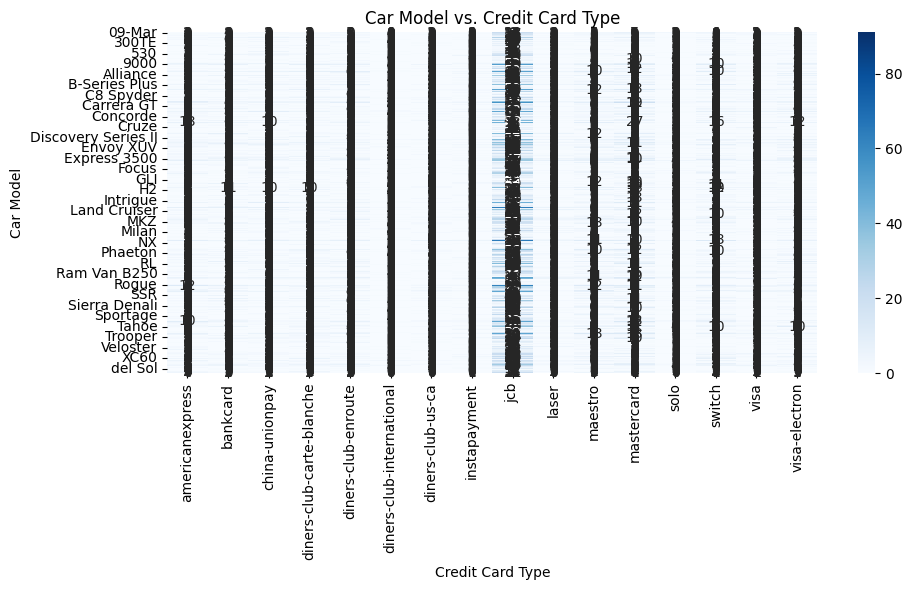

In [87]:
# Code for graphing

# Plot heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(table, annot=True, fmt="d", cmap="Blues")

plt.title("Car Model vs. Credit Card Type")
plt.xlabel("Credit Card Type")
plt.ylabel("Car Model")
plt.tight_layout()
plt.show()

After performing our Chi Squared Test, we recieved a p-value of approximatelt 0.992. This means that, under the assumption that Car Model and Credit Card Type are independent, we had a 99.2% probability of recieving our data. This is not below our alpha value, which means that our data is not sufficient to reject the null hypothesis. Hence, we conclude that there is an independent relationship between Car Model and Credit Card Type.

The heatmap we graphed also suggest as such, as there isn't much grouping between Car Model and Credit Card Type. However, the heat map does seem to suggest that jcb is the most reported Credit Card Type. This may be a data point worth considering.

# HYPOTHESIS TEST 2: Does mean car age differ between USA and China
We want to examine whether mean car age (year of manufacture) is different depending on if the buyer is from USA or China. To test this, a two sample t test will be used. Since we are comparing two countries, comparing means, car age is numeric, groups are indy, and pop sd is not known, two sample t test is best

https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html

In [88]:
df['Country'].value_counts()
df[df['Country'] == 'United States'].shape[0]

633

In [89]:
#get df for usa and china
usa_df = df[df['Country'] == 'United States']
china_df = df[df['Country'] == 'China']
usa_df.head()

,Name,Country,Car Brand,Car Model,Car Color,Year of Manufacture,Credit Card Type
12,Artemis Wrenn,United States,Hyundai,Elantra,Red,2000,maestro
130,Hasty Covolini,United States,Lamborghini,Countach,Crimson,1988,laser
177,Salomon Zanetto,United States,Toyota,Corolla,Crimson,2007,jcb
190,Josephine Torregiani,United States,Buick,Riviera,Violet,1985,laser
192,Cristiano Pummell,United States,Pontiac,LeMans,Goldenrod,1964,jcb


In [90]:
# use only years of manufacture for analysis
usa_years = usa_df['Year of Manufacture']
china_years = china_df['Year of Manufacture']
usa_years.head()

12     2000
130    1988
177    2007
190    1985
192    1964
Name: Year of Manufacture, dtype: int64

In [91]:
# get mean and std dev for usa and china
usa_mean = usa_years.mean()
china_mean = china_years.mean()

usa_std = usa_years.std()
china_std = china_years.std()

print("USA Mean:", usa_mean)
print("China Mean:", china_mean)
print("USA Std Dev:", usa_std)
print("China Std Dev:", china_std)

USA Mean: 2000.172195892575
China Mean: 2000.3096065873742
USA Std Dev: 9.542230473912353
China Std Dev: 9.279933025864178


In [92]:
# do a t-test to see if the means are significantly different
t, p = stats.ttest_ind(usa_years, china_years, equal_var=False)

In [93]:
print("t statistic:", t)
print("p-value:", p)

t statistic: -0.3439533090945807
p-value: 0.730974460775725


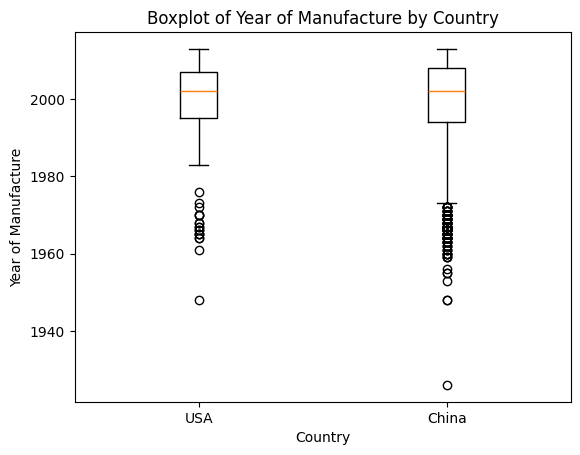

In [94]:
# make box plot to compare the distributions of year of manufacture for USA and China

plt.boxplot([usa_years, china_years])
plt.xticks([1, 2], ['USA', 'China'])
plt.title('Boxplot of Year of Manufacture by Country')
plt.xlabel('Country')
plt.ylabel('Year of Manufacture')
plt.show()

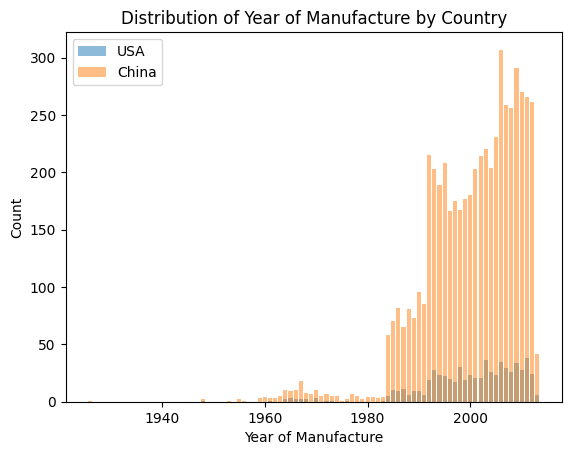

In [95]:
# make bar plot to compare the distributions of year of manufacture for USA and China
plt.bar(usa_years.value_counts().index, usa_years.value_counts().values, alpha=0.5, label='USA')
plt.bar(china_years.value_counts().index, china_years.value_counts().values, alpha=0.5, label='China')
plt.xlabel('Year of Manufacture')
plt.ylabel('Count')
plt.title('Distribution of Year of Manufacture by Country')
plt.legend()
plt.show()

Since the p value is .73 > .05, we fail to reject the null hypothesis. There was not statistically significant evidence that indicates the mean year of manufacture between USA and China is significanlty different. 

This can also be seen in the box plot. Although the spread of manufacture dates is different, with China having a heavier skew towards older cars than the USA, the means are roughly the same. The reasoning for this can be seen in the bar chart. Even though china has a larger spread from 1960 to 1980, they have a huge number of purchases made around 2000, bringing its mean back up 

# HYPOTHESIS TEST 3: Is the mean car age the same between the top 10 brands?
For our third hypothesis test, we would like to see whether the mean car year is the same between the top 10 brands (in count) for readability since there are 78 different brands. 

To do this, we will use anova because each brand is a group, meaning we will be testing 10 different groups. 


H0 : The mean car year is the same across all top 10 brands

HA : There is at least one brand that has a different mean car year


Significance level = 0.05 (conventional)

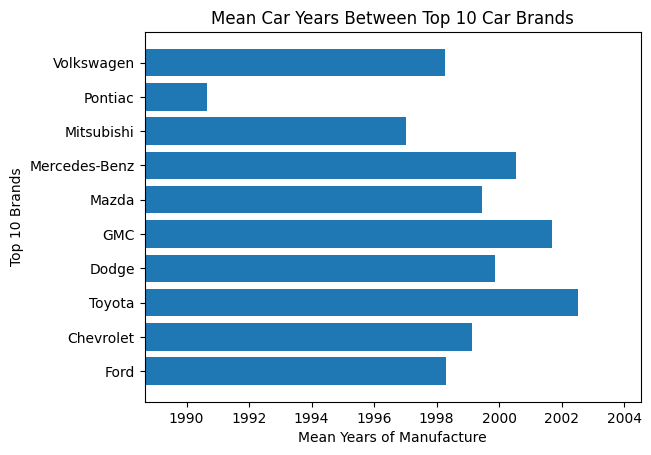

In [96]:
# Choose only top 10 brands by count

top10BrandValues = df["Car Brand"].value_counts().head(10)

top10Brands = top10BrandValues.index.tolist()

#print(f"Top 10 Car Brands in order: {top10Brands}")

grouped = df.groupby("Car Brand")

means = []

for brand in top10Brands:

    means.append(grouped.get_group(brand)["Year of Manufacture"].mean())

plt.barh(top10Brands, means)

plt.xlim(min(means)-2,max(means)+2)

plt.xlabel("Mean Years of Manufacture")
plt.ylabel("Top 10 Brands")
plt.title("Mean Car Years Between Top 10 Car Brands")

plt.show()

Here we can see that our graph has the smallest mean car year as about 1991 and the largest as about 2003. We can clearly see from this graph that while most mean car years are fairly close, there are really none that look truly identical except for Volkswagen and Ford which look to be about the same (this is just from observing the graph and is not fact). There is also a clear outlier which is pontiac which has a mean car year of about 1991 that differs by about 6 years to the next closest value which is Mitsubishi at about 1997. 

In [97]:

groupListForAnova = []

for brand in top10Brands:

    groupListForAnova.append(grouped.get_group(brand)["Year of Manufacture"])

# Use oneway Anova test
applied = f_oneway(*groupListForAnova)

print(f"P-Value: {applied.pvalue}")

P-Value: 1.1085060223372286e-265


As we can see from the p-value obtained, it is extremely small. Much smaller than our significance level of 0.05. This means that we will reject the null hypothesis. 

However, we do not know which group(s), specifically, differ, so we will also run a post-hoc test to determine those group(s).


In [98]:
# Apply the tukey post-hoc test to see which group means differ
applied = tukey_hsd(*groupListForAnova)

print(top10Brands)

display(applied.pvalue)

['Ford', 'Chevrolet', 'Toyota', 'Dodge', 'GMC', 'Mazda', 'Mercedes-Benz', 'Mitsubishi', 'Pontiac', 'Volkswagen']


array([[1.00000000e+00, 5.83561187e-02, 2.89357427e-12, 1.59657326e-05,
        2.89357427e-12, 2.14199607e-02, 6.56332433e-10, 4.91776107e-03,
        2.89357427e-12, 1.00000000e+00],
       [5.83561187e-02, 1.00000000e+00, 2.89357427e-12, 3.14496412e-01,
        2.94786417e-12, 9.94912540e-01, 7.86606089e-04, 1.86539084e-08,
        2.89357427e-12, 3.01051263e-01],
       [2.89357427e-12, 2.89357427e-12, 1.00000000e+00, 3.71458420e-12,
        3.33637669e-01, 2.89523960e-12, 3.75174641e-06, 2.89357427e-12,
        2.89357427e-12, 2.89357427e-12],
       [1.59657326e-05, 3.14496412e-01, 3.71458420e-12, 1.00000000e+00,
        1.73037314e-05, 9.75369368e-01, 7.07669403e-01, 3.81006338e-12,
        2.89357427e-12, 1.32774864e-03],
       [2.89357427e-12, 2.94786417e-12, 3.33637669e-01, 1.73037314e-05,
        1.00000000e+00, 1.10539065e-07, 8.43773903e-02, 2.89357427e-12,
        2.89357427e-12, 2.89390734e-12],
       [2.14199607e-02, 9.94912540e-01, 2.89523960e-12, 9.75369368e-01,
   

Interpretation: 

Ford = Group 0

Chevrolet = Group 1

Toyota = Group 2 

Dodge = Group 3

GMC = Group 4 

Mazda = Group 5

Mercedes-Benz = Group 6 

Mitsubishi = Group 7

Pontiac = Group 8 

Volkswagen = Group 9

Group 0 & 1 : 0.058 which is slightly greater than 0.05. This is greater than our significance level of 0.05, so it is not significant.

>Group 0 & 2 : Much less than 0.05. Significant.

>Group 0 & 3 : Much less than 0.05. Significant.

>Group 0 & 4 : Much less than 0.05. Significant.

>Group 0 & 5 : Less than 0.05. Significant.

>Group 0 & 6 : Much less than 0.05. Significant.

>Group 0 & 7 : Much less than 0.05. Significant.

>Group 0 & 8 : Much less than 0.05. Significant.

Group 0 & 9 : 1 which is much greater than 0.05. This is greater than our significance level of 0.05, so it is not significant.

>Group 1 & 2 : Much less than 0.05. Significant.

Group 1 & 3 : 0.3 which is much greater than 0.05. This is greater than our significance level of 0.05, so it is not significant.

>Group 1 & 4 : Much less than 0.05. Significant.

Group 1 & 5 : 0.9 which is much greater than 0.05. This is greater than our significance level of 0.05, so it is not significant.

>Group 1 & 6 : Much less than 0.05. Significant.

>Group 1 & 7 : Much less than 0.05. Significant.

>Group 1 & 8 : Much less than 0.05. Significant.

Group 1 & 9 : 0.3 which is much greater than 0.05. This is greater than our significance level of 0.05, so it is not significant.

>Group 2 & 3 : Much less than 0.05. Significant.

Group 2 & 4 : 0.3 which is slightly greater than 0.05. This is greater than our significance level of 0.05, so it is not significant.

>Group 2 & 5 : Much less than 0.05. Significant.

>Group 2 & 6 : Much less than 0.05. Significant.

>Group 2 & 7 : Much less than 0.05. Significant.

>Group 2 & 8 : Much less than 0.05. Significant.

>Group 2 & 9 : Much less than 0.05. Significant.

>Group 3 & 4 : Much less than 0.05. Significant.

Group 3 & 5 : 0.9 which is much greater than 0.05. This is greater than our significance level of 0.05, so it is not significant.

Group 3 & 6 : 0.7 which is much greater than 0.05. This is greater than our significance level of 0.05, so it is not significant.

>Group 3 & 7 : Much less than 0.05. Significant.

>Group 3 & 8 : Much less than 0.05. Significant.

>Group 3 & 9 : Much less than 0.05. Significant.

>Group 4 & 5 : Much less than 0.05. Significant.

Group 4 & 6 : 0.08 which is slightly greater than 0.05. This is greater than our significance level of 0.05, so it is not significant.

>Group 4 & 7 : Much less than 0.05. Significant.

>Group 4 & 8 : Much less than 0.05. Significant.

>Group 4 & 9 : Much less than 0.05. Significant.

Group 5 & 6 : 0.1 which is much greater than 0.05. This is greater than our significance level of 0.05, so it is not significant.

>Group 5 & 7 : Much less than 0.05. Significant.

>Group 5 & 8 : Much less than 0.05. Significant.

Group 5 & 9 : 0.1 which is much greater than 0.05. This is greater than our significance level of 0.05, so it is not significant.

>Group 6 & 7 : Much less than 0.05. Significant.

>Group 6 & 8 : Much less than 0.05. Significant.

>Group 6 & 9 : Much less than 0.05. Significant.

>Group 7 & 8 : Much less than 0.05. Significant.

Group 7 & 9 : 0.07 which is slightly greater than 0.05. This is greater than our significance level of 0.05, so it is not significant.

>Group 8 & 9 : Much less than 0.05. Significant.

There were 45 total comparisons, and 33 of them proved to be significant. Most notably, Group 8 (Pontiac), had very strong evidence for a difference in mean car year compared to the rest of the 9 brands (since any comparison that included Pontiac always had a significant value). A possible explanation for this is that Pontiac officially shut down and produced their final car in 2010, meanwhile all of the other brands are still currently operating. 

Groups 0 & 1 (Ford & Chevrolet), 0 & 9 (Ford & Volkswagen), 1 & 3 (Chevrolet & Dodge), 1 & 5 (Chevrolet & Mazda), 1 & 9 (Chevrolet & Volkswagen), 2 & 4 (Toyota & GMC), 3 & 5 (Dodge & Mazda), 
3 & 6 (Dodge & Mercedes-Benz), 4 & 6 (GMC & Mercedes-Benz), 5 & 6 (Mazda & Mercedes-Benz), 5 & 9 (Mazda & Volkswagen), and 7 & 9 (Mitsubishi & Volkswagen) make up 12 of the 45 comparisons made. Each of these comparisons did not have enough evidence (non-significant p values) to prove that the mean car years were different at significance level = 0.05. 

However, for the remaining 33 comparisons, they had significant p values, indicating that there is strong evidence for many of these brands to have differing mean car years compared to one another.